# SGD NEER: fixed clocks versus rolling signals

The previous multi-day study used **16:00 New York**. This extension tests five daily clocks and signals that can trigger at any available minute, from 6 hours to 10 market days. Positions can remain open overnight and over weekends. All net Sharpes deduct spreads; **forward points remain excluded**.

The 80 configurations include controls that review identical rolling features only at 16:00. The evaluation period was already inspected, so the results are exploratory. [Full report and methods](sgd_neer_timing_report.md).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

research = next(p/s for p in [Path.cwd(), *Path.cwd().parents]
                for s in ['', 'src/systematic_trading/research/sgd_neer_codex']
                if (p/s/'sgd_neer_results/timing/comparison.csv').exists())
results = research/'sgd_neer_results/timing'
comparison = pd.read_csv(results/'comparison.csv')
base = comparison.query('fill_delay_minutes == 0')
final = base.query("period == 'evaluation'").set_index('policy')
scores = base.pivot(index='policy', columns='period', values='sharpe')
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':10})
print(json.loads((results/'protocol.json').read_text())['financing'])


Forward points explicitly excluded at user request.


## Alternate daily clocks

Each cell shows 2024–2025 net Sharpe and completed trades. The eight 16:00 controls exactly reproduce the prior multi-day study. Clocks use New York local time, including seasonal UTC-offset changes.

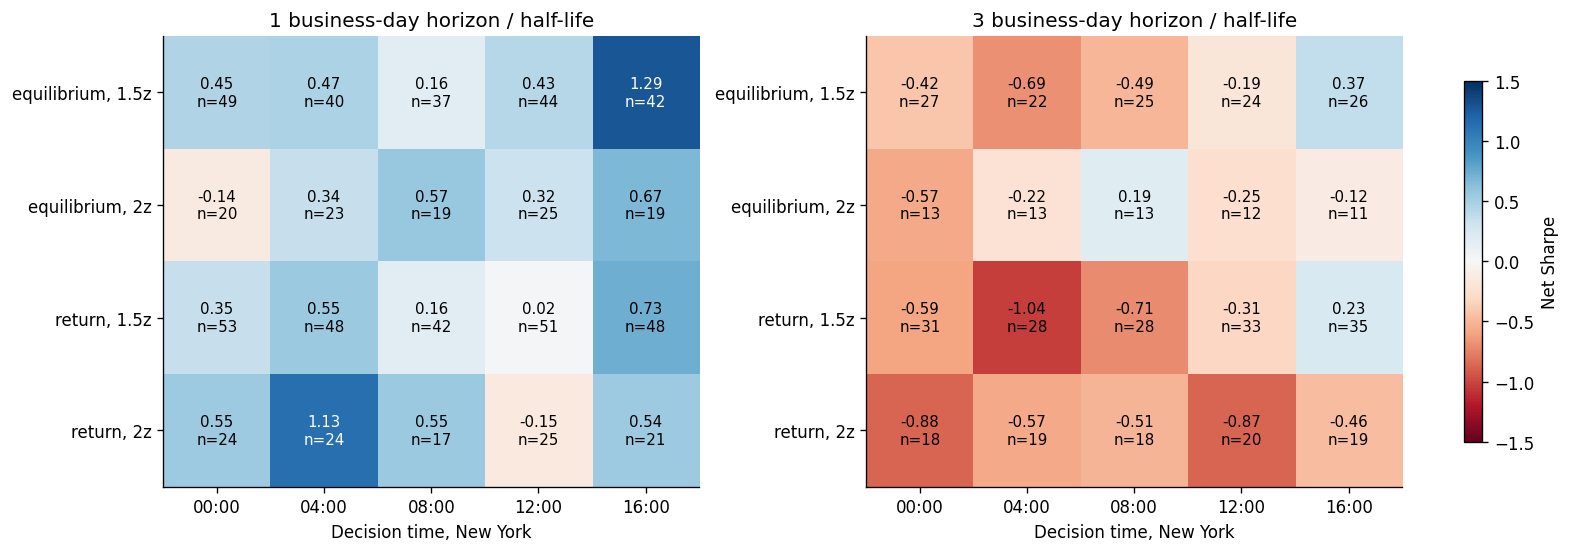

In [2]:
fig, axes = plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for ax, hours in zip(axes, [24,72]):
    part = final.query("family == 'daily' and horizon_hours == @hours")
    values = part.pivot(index=['kind','entry_z'],columns='hour_ny',values='sharpe')
    counts = part.pivot(index=['kind','entry_z'],columns='hour_ny',values='completed_trades')
    im = ax.imshow(values,cmap='RdBu',vmin=-1.5,vmax=1.5,aspect='auto')
    for i in range(len(values)):
        for j in range(len(values.columns)):
            value = values.iloc[i,j]
            ax.text(j,i,f'{value:.2f}\nn={counts.iloc[i,j]}',ha='center',va='center',fontsize=9,
                    color='white' if abs(value)>1.05 else 'black')
    ax.set_xticks(range(5),[f'{int(h):02d}:00' for h in values.columns])
    ax.set_yticks(range(4),[f'{k}, {z:g}z' for k,z in values.index])
    ax.set(title=f'{hours//24} business-day horizon / half-life',xlabel='Decision time, New York')
fig.colorbar(im,ax=axes,label='Net Sharpe',shrink=.8)
fig.savefig(results/'daily_clock_sensitivity.png',dpi=160)
plt.show()


## Rolling signals: identical features, different review frequency

Continuous rules can enter and exit on every available minute. The controls review the same features at 16:00; known timeouts apply to both at any minute. Market hours exclude the weekend closure and retain missing minutes. For return reversal H is the trailing return window; for equilibrium H is the EWMA half-life.

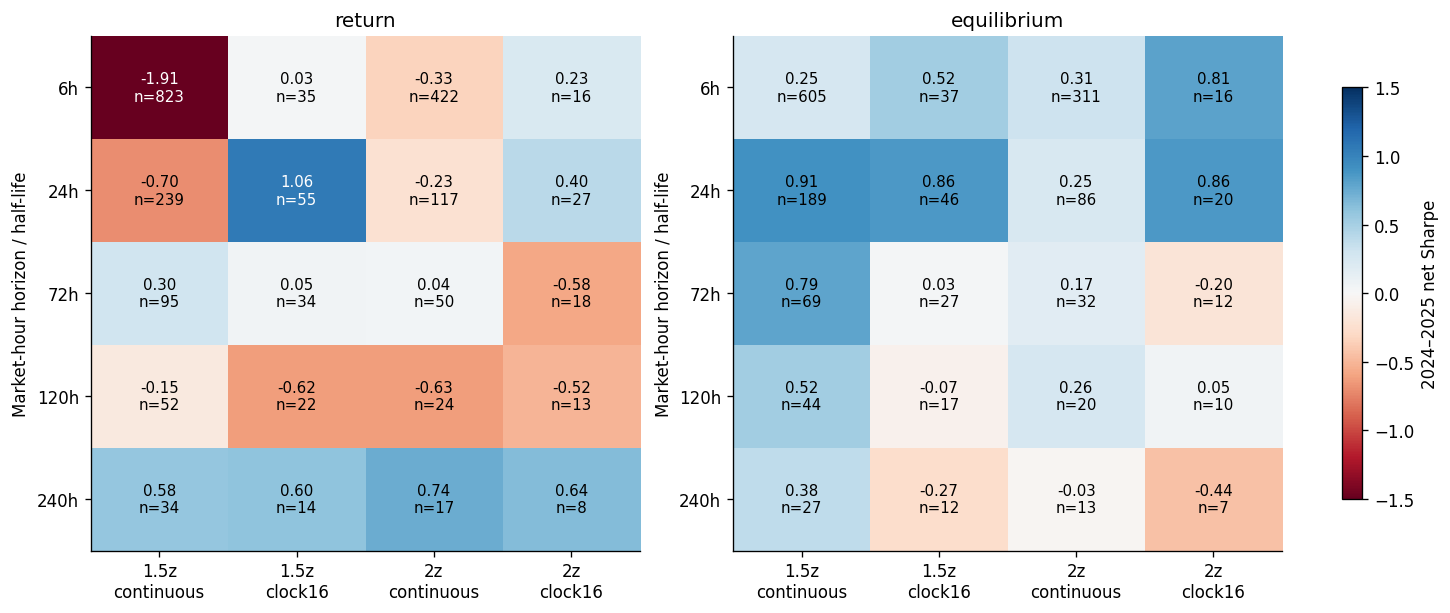

,kind,horizon_hours,entry_z,gross_sharpe,sharpe,completed_trades
policy,,,,,,
rolling_return_6h_z1.5_continuous,return,6,1.5,4.212,-1.906,823
rolling_return_6h_z2_continuous,return,6,2.0,3.274,-0.334,422
rolling_return_24h_z1.5_continuous,return,24,1.5,1.991,-0.698,239
rolling_return_24h_z2_continuous,return,24,2.0,1.478,-0.228,117
rolling_return_72h_z1.5_continuous,return,72,1.5,1.132,0.303,95
rolling_return_72h_z2_continuous,return,72,2.0,0.566,0.045,50
rolling_return_120h_z1.5_continuous,return,120,1.5,0.311,-0.147,52
rolling_return_120h_z2_continuous,return,120,2.0,-0.343,-0.627,24
rolling_return_240h_z1.5_continuous,return,240,1.5,0.888,0.578,34


In [3]:
fig, axes = plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax, kind in zip(axes,['return','equilibrium']):
    part = final.query("family == 'rolling' and kind == @kind")
    values = part.pivot(index='horizon_hours',columns=['entry_z','review'],values='sharpe')
    counts = part.pivot(index='horizon_hours',columns=['entry_z','review'],values='completed_trades')
    im = ax.imshow(values,cmap='RdBu',vmin=-1.5,vmax=1.5,aspect='auto')
    for i in range(len(values)):
        for j in range(len(values.columns)):
            value = values.iloc[i,j]
            ax.text(j,i,f'{value:.2f}\nn={counts.iloc[i,j]}',ha='center',va='center',fontsize=9,
                    color='white' if abs(value)>1.05 else 'black')
    ax.set_xticks(range(4),[f'{z:g}z\n{r}' for z,r in values.columns])
    ax.set_yticks(range(5),[f'{h}h' for h in values.index])
    ax.set(title=kind,ylabel='Market-hour horizon / half-life')
fig.colorbar(im,ax=axes,label='2024–2025 net Sharpe',shrink=.8)
fig.savefig(results/'rolling_review_comparison.png',dpi=160)
plt.show()
display(final.query("family == 'rolling' and review == 'continuous'")[['kind','horizon_hours','entry_z','gross_sharpe','sharpe','completed_trades']].round(3))


## Stability through time

The examples below are transparent controls and illustrative horizons, supplemented by the predeclared development-only shortlist. 2023 quote coverage is incomplete. A high 2024–2025 score is not an independently validated optimum.

Development-only shortlist: ['rolling_equilibrium_24h_z1.5_continuous', 'rolling_equilibrium_6h_z2_continuous', 'rolling_equilibrium_24h_z2_continuous']


period,development,recent_development,validation,2024,2025,evaluation,all_2017_2025
policy,,,,,,,
clock16_return_1d_z1.5,0.901,0.929,0.392,1.263,0.252,0.729,0.811
clock16_return_1d_z2,0.930,1.390,0.316,0.966,0.215,0.544,0.778
clock04_return_1d_z2,0.244,-0.227,0.264,1.500,0.864,1.132,0.401
clock16_equilibrium_1d_z1.5,0.058,0.244,0.794,1.940,0.658,1.286,0.380
rolling_return_24h_z2_continuous,0.901,0.958,1.475,0.470,-1.031,-0.228,0.713
rolling_return_24h_z2_clock16,0.927,1.007,0.336,0.964,-0.097,0.403,0.738
rolling_return_72h_z2_continuous,0.492,1.405,0.774,0.480,-0.377,0.045,0.406
rolling_return_120h_z2_continuous,0.238,0.358,1.160,-0.241,-0.934,-0.627,0.095
rolling_return_240h_z2_continuous,0.259,1.383,2.250,1.108,0.401,0.742,0.510


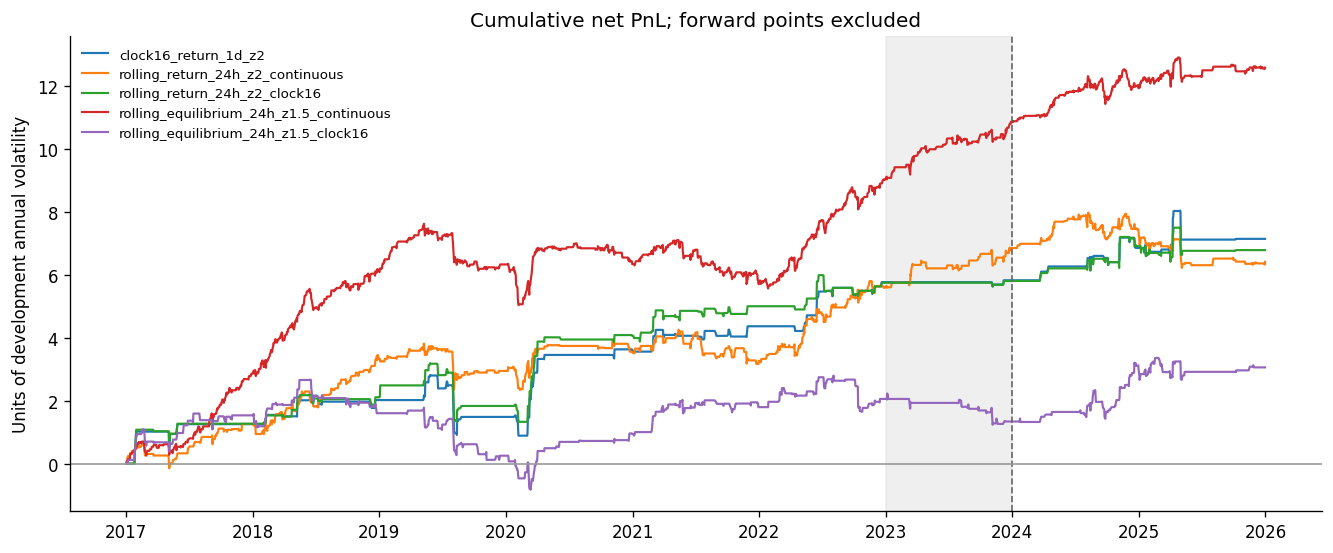

,policy,development,recent_development,validation,validation_completed_trades,validation_active_days,score,eligible
0,rolling_equilibrium_24h_z1.5_continuous,1.454,1.259,2.045,68,110,1.259,True
1,rolling_equilibrium_6h_z2_continuous,1.064,1.107,1.876,103,100,1.064,True
2,rolling_equilibrium_24h_z2_continuous,0.924,1.203,0.988,23,44,0.924,True
3,rolling_return_24h_z2_continuous,0.901,0.958,1.475,36,56,0.901,True
4,rolling_equilibrium_6h_z1.5_continuous,0.701,0.986,2.606,240,177,0.701,True
5,clock16_return_3d_z1.5,0.554,1.514,0.781,7,27,0.554,False
6,rolling_return_240h_z1.5_continuous,0.516,0.713,1.171,11,85,0.516,True
7,rolling_return_72h_z2_continuous,0.492,1.405,0.774,11,36,0.492,False
8,rolling_return_24h_z1.5_continuous,0.505,0.485,0.926,94,122,0.485,True
9,clock16_return_3d_z2,0.416,1.955,0.671,1,4,0.416,False


In [4]:
names = ['clock16_return_1d_z1.5', 'clock16_return_1d_z2', 'clock04_return_1d_z2', 'clock16_equilibrium_1d_z1.5', 'rolling_return_24h_z2_continuous', 'rolling_return_24h_z2_clock16', 'rolling_return_72h_z2_continuous', 'rolling_return_120h_z2_continuous', 'rolling_return_240h_z2_continuous', 'rolling_equilibrium_24h_z2_continuous', 'rolling_equilibrium_24h_z1.5_continuous', 'rolling_equilibrium_6h_z2_continuous']
display(scores.loc[names,['development', 'recent_development', 'validation', '2024', '2025', 'evaluation', 'all_2017_2025']].round(3))
fig, ax = plt.subplots(figsize=(11,4.5),layout='constrained')
for name in ['clock16_return_1d_z2','rolling_return_24h_z2_continuous','rolling_return_24h_z2_clock16','rolling_equilibrium_24h_z1.5_continuous','rolling_equilibrium_24h_z1.5_clock16']:
    daily = pd.read_csv(results/f'daily_{name}_fill0.csv.gz',index_col=0,parse_dates=True).net
    scale = daily.loc['2017':'2022'].std()*np.sqrt(252)
    ax.plot(daily.loc['2017':].cumsum()/scale,label=name,lw=1.3)
ax.axvspan(pd.Timestamp('2023-01-01'),pd.Timestamp('2024-01-01'),color='0.8',alpha=.3)
ax.axvline(pd.Timestamp('2024-01-01'),color='0.4',ls='--',lw=1)
ax.axhline(0,color='0.6',lw=1)
ax.set(title='Cumulative net PnL; forward points excluded',ylabel='Units of development annual volatility')
ax.legend(frameon=False,fontsize=8)
fig.savefig(results/'timing_cumulative_pnl.png',dpi=160)
plt.show()
display(pd.read_csv(results/'leaderboard.csv').head(15).round(3))
print('Development-only shortlist:',json.loads((results/'frozen_selection.json').read_text())['selected'])


## Are entries actually distributed across the day?

Actual 2024–2025 fills for continuously monitored 24-market-hour rules at 2z. There is no hour filter on entry; sparse entry patterns reflect when signal thresholds and spread hurdles are met.

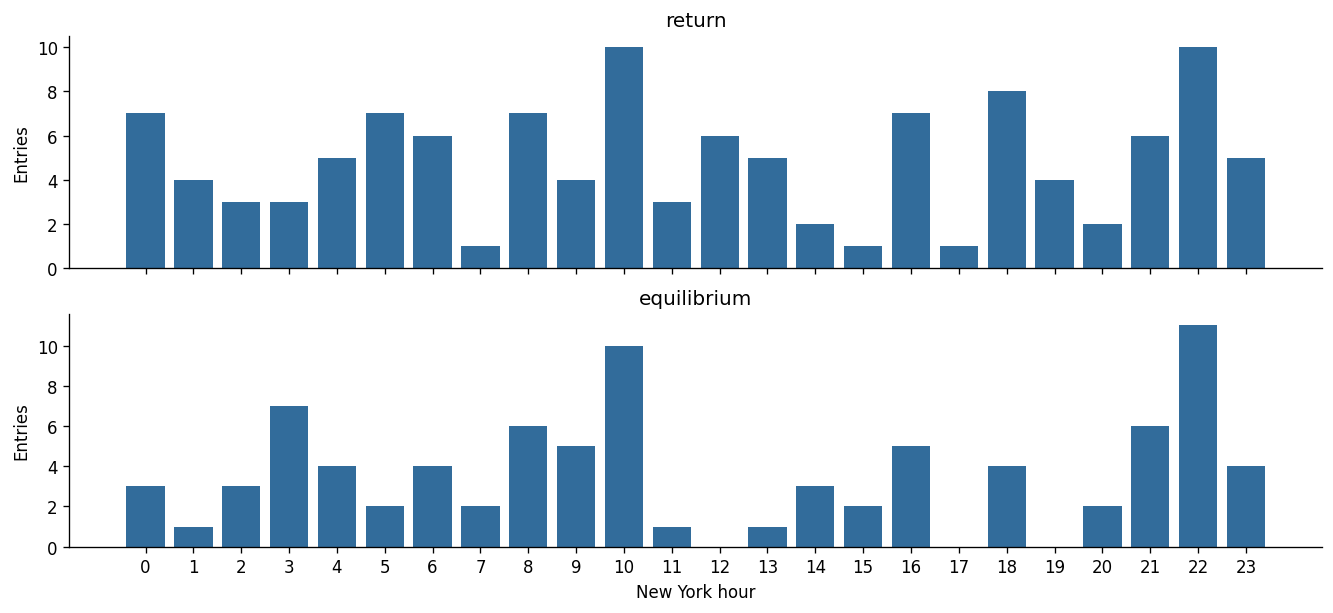

In [5]:
hours = pd.read_csv(results/'entry_hours.csv')
fig, axes = plt.subplots(2,1,figsize=(11,5),sharex=True,layout='constrained')
for ax, kind in zip(axes,['return','equilibrium']):
    name = f'rolling_{kind}_24h_z2_continuous'
    part = hours[hours.policy == name]
    ax.bar(part.hour_ny,part.entries,color='#326c9b')
    ax.set(title=kind,ylabel='Entries')
axes[-1].set_xticks(range(24))
axes[-1].set_xlabel('New York hour')
fig.savefig(results/'entry_hour_distribution.png',dpi=160)
plt.show()


## Costs, delay, uncertainty and missing marks

Delay is one subsequent common valid quote, which may exceed one elapsed minute across missing data. Block-bootstrap intervals do not adjust for the strategy search. The exporter can forward fill quotes by up to ten minutes; this study adds no filling. No financing, commission or market impact is in the base case.

In [6]:
stress = pd.read_csv(results/'stress.csv')
display(comparison[(comparison.period == 'evaluation') & comparison.policy.isin(names)].pivot(index='policy',columns='fill_delay_minutes',values='sharpe').round(3))
display(stress[(stress.fill_delay_minutes == 0) & stress.policy.isin(names)].pivot(index='policy',columns='scenario',values='sharpe').round(3))
display(pd.read_csv(results/'bootstrap.csv').set_index('policy').loc[names].round(3))
coverage = pd.read_csv(results/'coverage.csv')
display(coverage[(coverage.iloc[:,0] == 2023) & coverage['mode'].isin(['daily_clock','rolling_grid'])].round(3))


fill_delay_minutes,0,1
policy,,
clock04_return_1d_z2,1.132,1.207
clock16_equilibrium_1d_z1.5,1.286,1.289
clock16_return_1d_z1.5,0.729,0.687
clock16_return_1d_z2,0.544,0.541
rolling_equilibrium_24h_z1.5_continuous,0.907,0.321
rolling_equilibrium_24h_z2_continuous,0.246,-0.019
rolling_equilibrium_6h_z2_continuous,0.309,-0.652
rolling_return_120h_z2_continuous,-0.627,-0.545
rolling_return_240h_z2_continuous,0.742,0.760


scenario,base,extra_0.25bp_per_leg,spread_x2
policy,,,
clock04_return_1d_z2,1.132,0.976,0.858
clock16_equilibrium_1d_z1.5,1.286,1.117,0.882
clock16_return_1d_z1.5,0.729,0.517,0.190
clock16_return_1d_z2,0.544,0.433,0.317
rolling_equilibrium_24h_z1.5_continuous,0.907,0.321,-1.162
rolling_equilibrium_24h_z2_continuous,0.246,-0.087,-0.957
rolling_equilibrium_6h_z2_continuous,0.309,-0.765,-2.669
rolling_return_120h_z2_continuous,-0.627,-0.714,-0.904
rolling_return_240h_z2_continuous,0.742,0.687,0.586


,low,median,high,draws,nonzero_vol_draws,zero_vol_draws
policy,,,,,,
clock16_return_1d_z1.5,-0.366,0.723,1.829,2000,2000,0
clock16_return_1d_z2,-0.832,0.591,1.771,2000,2000,0
clock04_return_1d_z2,-0.411,1.180,2.622,2000,2000,0
clock16_equilibrium_1d_z1.5,0.091,1.302,2.388,2000,2000,0
rolling_return_24h_z2_continuous,-1.446,-0.238,1.144,2000,2000,0
rolling_return_24h_z2_clock16,-0.756,0.428,1.427,2000,2000,0
rolling_return_72h_z2_continuous,-1.435,0.021,1.491,2000,2000,0
rolling_return_120h_z2_continuous,-1.713,-0.624,0.550,2000,2000,0
rolling_return_240h_z2_continuous,-0.367,0.748,2.018,2000,2000,0


,index,count,sum,mean,mode,hour_ny
7,2023,260,258,0.992,daily_clock,0.0
17,2023,260,258,0.992,daily_clock,4.0
27,2023,260,146,0.562,daily_clock,8.0
37,2023,260,147,0.565,daily_clock,12.0
47,2023,260,148,0.569,daily_clock,16.0
57,2023,371640,287566,0.774,rolling_grid,NaN


## Reproduce or change the horizon

```sh
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_timing.py
```

After adding `src/systematic_trading` to the Python path:

```python
from research.sgd_neer_codex.sgd_neer_timing import rolling_marks, rolling_features, RollingPolicy, rolling_signal
from research.sgd_neer_codex.sgd_neer_multiday import MinuteAccountant
data = pd.read_pickle('tmp/sgd_neer_m1_research/data.pkl')
assert data.freq == pd.Timedelta(minutes=1)
marks = rolling_marks(data)
features = rolling_features(marks, 'return', 24)
policy = RollingPolicy('custom', 'return', horizon_hours=24, entry_z=2., review_hour=None)
signal = rolling_signal(marks, features, policy)
daily, trades = MinuteAccountant(data).run(signal, delay=0)
```

The maximum holding time is twice the horizon. Set `review_hour=16` for the matched daily-review control. All input quotes and accounting remain at one-minute frequency. See the full report for the distinction between market hours and elapsed calendar hours.